### The complex Ginzburg-Landau model, with Gonfalon domains, defects generated on boundary

In [ ]:
import numpy as np

import ngsolve 
from ngsolve.webgui import Draw
import netgen.geom2d

import math
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import importlib
import copy # for copying objects (like meshes!)
%matplotlib inline

import cgle  # many subroutines moved here 

notebookroot = 'CGLE_pin_v00_'  # for output files

# some more globals
bndparms = []

korder=3
dt = 0.04 # timestep
bndlist0 = 'p1_bottom_left|p1_bottom_right|p1_left|p1_right'  # list of boundaries for Dirichlet BC

# for figures
labelpos = [0.03,0.98] 
figsize=(7,5) 
cbar_shrink = 0.5
figparms = ['',labelpos,figsize,cbar_shrink]


In [ ]:
importlib.reload(cgle)  # if you are working on the helper routines

$$ \partial_t A = A - (b_3 - i) |A|^2 A + (1 + i b_1) \Delta A \ \ \text{Chat\'e review form}$$  
$$ \partial_t A = A - (1+ i\beta) |A|^2 A + (1 + i \alpha) \Delta A \ \ \text{Aranson review form}$$  

We assume that $\alpha,\beta, b_3, b_1, \in {\mathbb R}$.  Also we require that $b_3>0$. 
The field $A \in {\mathbb C}$ and $A({\bf x}, t)$ with $t$ time and ${\bf x} \in {\mathbb R}^2$.

To transform from Chat\'e to Aranson form 
\begin{align}
\alpha &= b_1,  A' = A |b_3|^{1/2} , \beta = -1/b_3 \qquad \text{ for } b_3 >0
\end{align} 
where $A$ and $A'$ are the amplitudes in Chat\'e and Aranson forms, respectively. 
To transform from Aranson form to Chat\'e form
\begin{align}
b_1 &= -\text{sign}(\beta) \alpha, A = A'|\beta|^{1/2}, b_3 = 1/|\beta|  .
\end{align} 





https://forum.ngsolve.org/t/hdg-method-for-the-stokes-with-non-homogeneous-dirichlet-boundary-condition/2833
 
https://ngsolve.org/forum/ngspy-forum/1308-specifying-inconsisten-initial-and-boundary-conditions

It is possible to set individual coefficient functions on different boundaries.

See  https://docu.ngsolve.org/latest/i-tutorials/unit-1.5-subdomains/subdomains.html#Extra-exercises-to-try-out



In [4]:
#It is possible to set individual coefficient functions on different boundaries
#See  https://docu.ngsolve.org/latest/i-tutorials/unit-1.5-subdomains/subdomains.html#Extra-exercises-to-try-out

# routine to set Dirichlet boundaries
def mkbnd_lr(fes,mesh,bl_real=-1.1):
    bl_imag = 0;  br_imag = 0;  l_imag = 0.0;r_imag = 0.0
    #bl_real = -1.1
    br_real = -bl_real
    l_real = bl_real
    r_real = -l_real
    gfu_bnd = ngsolve.GridFunction(fes) 
    bdry_values_real = {'p1_bottom_left': bl_real, 'p1_bottom_right': br_real, 'p1_left': l_real,'p1_right': r_real}
    bdry_values_imag = {'p1_bottom_left': bl_imag, 'p1_bottom_right': br_imag, 'p1_left': l_imag,'p1_right': r_imag}
    cf_real  = mesh.BoundaryCF(bdry_values_real, default=0)
    cf_imag  = mesh.BoundaryCF(bdry_values_imag, default=0)
    gfu_bnd = ngsolve.GridFunction(fes) 
    gfu_bnd.components[0].Set(cf_real,definedon=mesh.Boundaries('p1_bottom_left|p1_bottom_right|p1_left|p1_right')) 
    gfu_bnd.components[1].Set(cf_imag,definedon=mesh.Boundaries('p1_bottom_left|p1_bottom_right|p1_left|p1_right')) 
    return gfu_bnd

('p1_bottom_left', 'p1_bottom_right', 'p1_right', 'p1_top', 'p1_left')


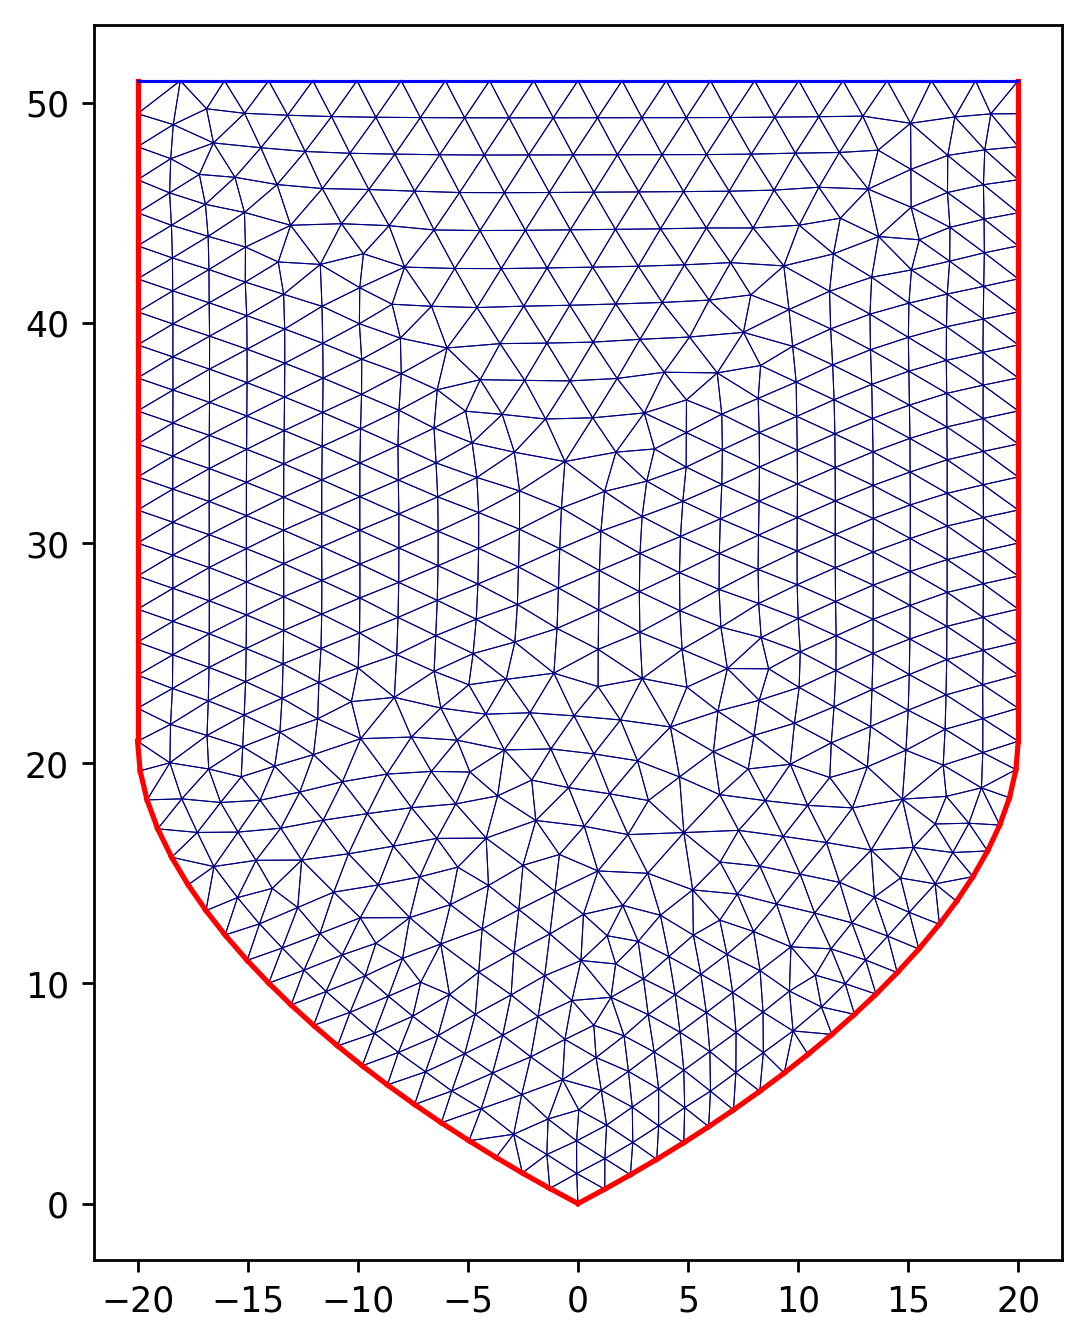

In [168]:
# create domain
geo = netgen.geom2d.CSG2d()

# create a rectangle 
hx = 40.0
hy = 30.0
zlow = -hx/2 -1 # -21
fac=1
poly1 = netgen.geom2d.Solid2d( [
    (0,0),
    netgen.geom2d.EdgeInfo((0, zlow/2 *fac),bc="p1_bottom_left",maxh=1.3*fac), # set bc name for segment (0,0)-(hx/2,0) and make spline3 
    (hx/2*fac,zlow*fac),
    netgen.geom2d.EdgeInfo((hx*fac,zlow/2*fac),bc="p1_bottom_right",maxh=1.3*fac), # set bc name for segment (0,0)-(hx,0) and make spline3 
    (hx*fac,0),
    netgen.geom2d.EdgeInfo(bc="p1_right",maxh=1.5*fac),  # set bc for segment (hx,0)-(hx,hy)
    (hx*fac,hy*fac),
    netgen.geom2d.EdgeInfo(bc="p1_top"),  # set bc for segment (hx,hy)-(0,hy)
    (0,hy*fac),
    netgen.geom2d.EdgeInfo(bc="p1_left",maxh=1.5*fac), # set bc for segment (0,hy)-(0,0)
    ] )
poly1.Move((-hx/2*fac,-zlow*fac))  # center the rectangle in x and put apex at 0 in y
geo.Add(poly1)
# for splines you need to choose the intermediate point carefully.  Here we make it closer to the outer point
# so that the corner is not as much affected and is a corner 

maxhval = 2.0*fac
mesh = ngsolve.Mesh(geo.GenerateMesh(maxh=maxhval))
print(mesh.GetBoundaries())

cgle.draw_mesh(mesh,ofile=notebookroot+'mesh1.png',figsize=(5,7),d_boundaries='p1_bottom_left|p1_bottom_right|p1_right|p1_left',\
              n_boundaries='p1_top')  

In [79]:
fes = cgle.mkfes(mesh,korder,bndlist0) # make finite element system, with Dirichlet boundary 
gfu = ngsolve.GridFunction(fes) # make the field to hold the solution 
gfu_bnd = mkbnd_lr(fes,mesh,bl_real=-1.1)  # create boundary vals (fixed, non-zero Dirichlet)

sig = 0.01
cgle.gen_init(gfu,mesh,0,sig,maxhval,A_r0=0.9,A_i0=0)  # generate interior initial conditions gen_init(gfu,mesh,nseeds,sig,hseeds):
# the A_r0, A_i0 are the mean initial field value 

cgle.set_on_boundary(gfu,gfu_bnd,fes) # update all dirichlet boundaries on gfu using gfu_bnd
scene=Draw(cgle.norm_gfu(gfu),mesh, min=0,max=1.2,\
           settings = {  "Colormap" : { "ncolors" : 20 } , "Objects" : {"Wireframe" : False}})

time = 0

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Colormap': {'ncolors': 20}, …

In [80]:
#importlib.reload(cgle)  # if you are working on the helper routines 
alpha = 2; beta = 0.2  # choose a nice pattern, Aranson form of PDE
clabel = r'$\alpha=${:.1f}, '.format(alpha) + r'$\beta=${:.1f}'.format(beta) 
figparms[0] = clabel

invastar, a_lap, b_op, minv  = cgle.mk_ops(fes,alpha,dt)  # construct operators 
ofileroot = notebookroot+'_a1c_'
cgle.Aranson_to_Chate(alpha,beta)

time = cgle.TimeStepping_CN(fes,gfu,scene,invastar, a_lap,minv,beta, dt, t0=time,tdur=200,nsamples = 200,gfun_op = True,uform='Aran',\
                         poutput=True,ofileroot=ofileroot,figparms=figparms)
# works if gfun_op = True, and False and if we used either form of the non-linear operator as of 10/20/2026 


 b_1=-2.00 b_3 =5.00
craete bilinearformapplication
 1.000  CGLE_pin_v00__a1c_000.png
 2.040  CGLE_pin_v00__a1c_001.png
 3.080  CGLE_pin_v00__a1c_002.png
 4.120  CGLE_pin_v00__a1c_003.png
 5.160  CGLE_pin_v00__a1c_004.png
 6.200  CGLE_pin_v00__a1c_005.png
 7.240  CGLE_pin_v00__a1c_006.png
 8.280  CGLE_pin_v00__a1c_007.png
 9.320  CGLE_pin_v00__a1c_008.png
 10.360  CGLE_pin_v00__a1c_009.png
 11.400  CGLE_pin_v00__a1c_010.png
 12.440  CGLE_pin_v00__a1c_011.png
 13.480  CGLE_pin_v00__a1c_012.png
 14.520  CGLE_pin_v00__a1c_013.png
 15.560  CGLE_pin_v00__a1c_014.png
 16.600  CGLE_pin_v00__a1c_015.png
 17.640  CGLE_pin_v00__a1c_016.png
 18.680  CGLE_pin_v00__a1c_017.png
 19.720  CGLE_pin_v00__a1c_018.png
 20.760  CGLE_pin_v00__a1c_019.png
 21.800  CGLE_pin_v00__a1c_020.png
 22.840  CGLE_pin_v00__a1c_021.png
 23.880  CGLE_pin_v00__a1c_022.png
 24.920  CGLE_pin_v00__a1c_023.png
 25.960  CGLE_pin_v00__a1c_024.png
 27.000  CGLE_pin_v00__a1c_025.png
 28.040  CGLE_pin_v00__a1c_026.png
 29.080  CGL

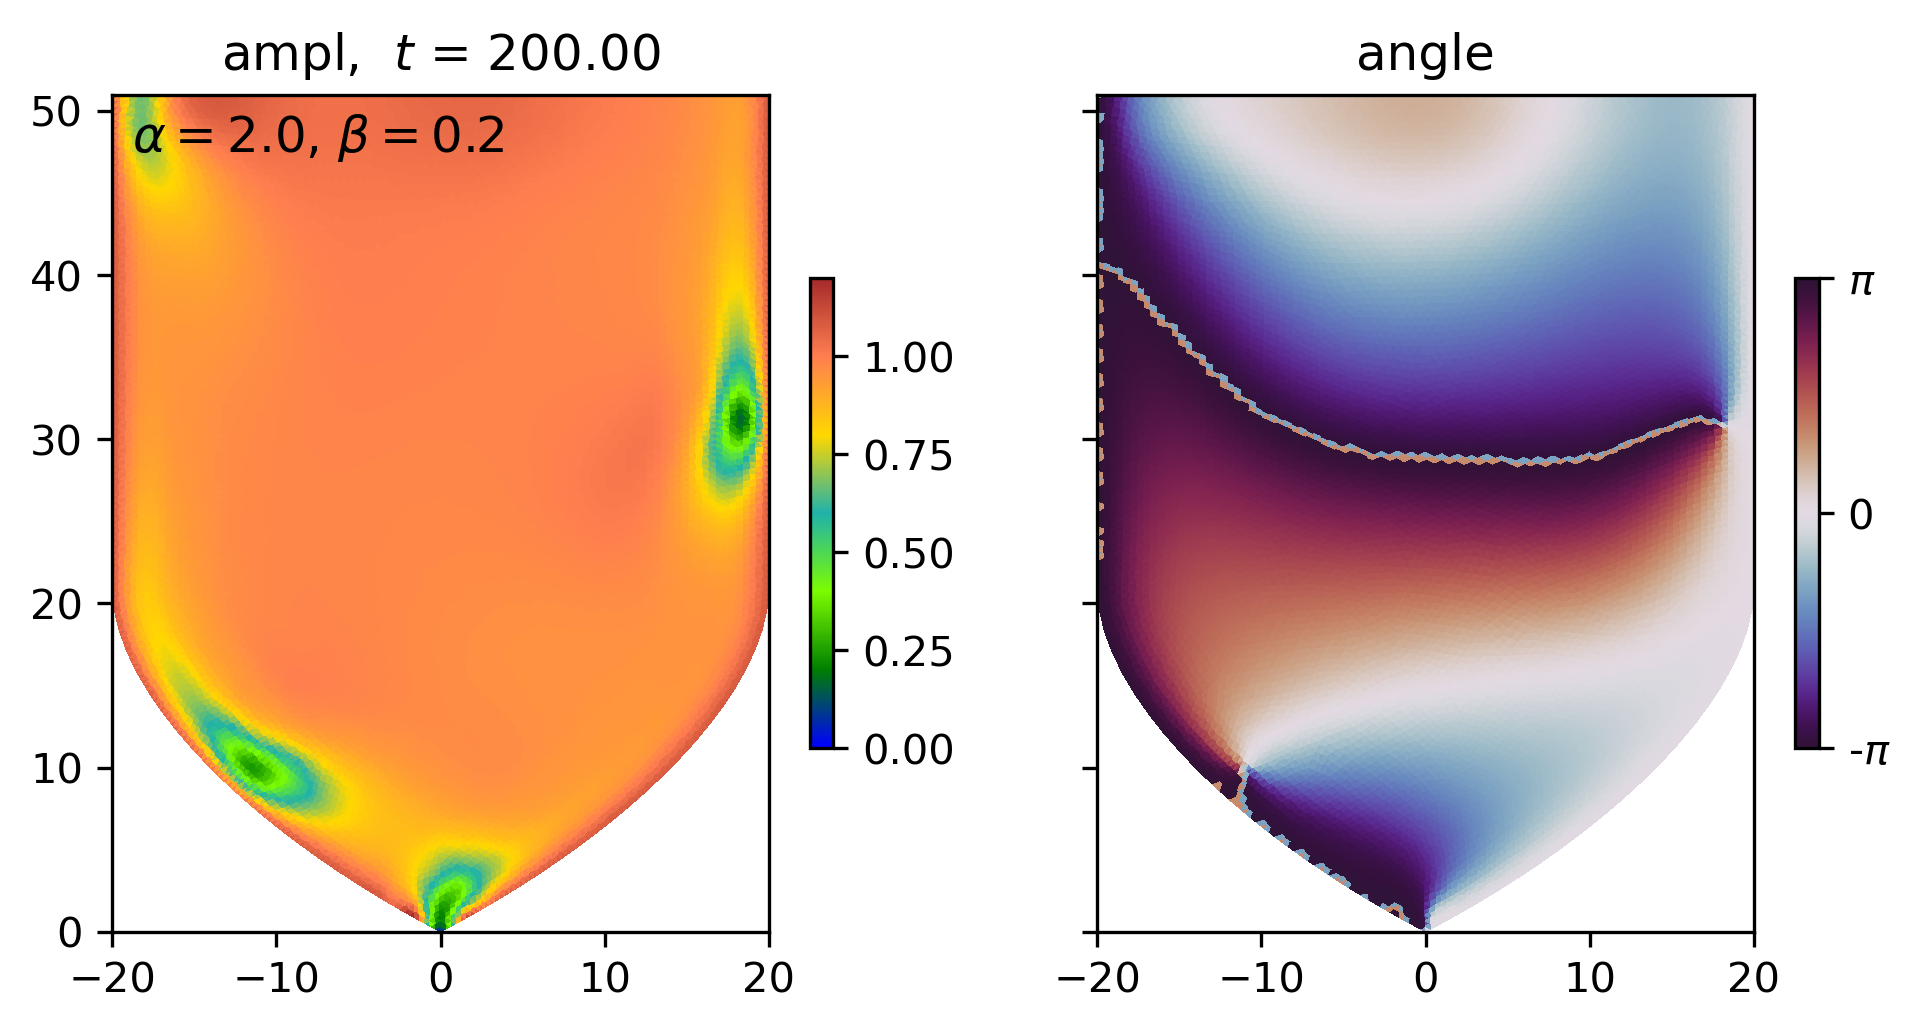

In [81]:
ofile = ofileroot + '_snap.png'
cgle.disp(mesh,gfu,time,ofile=ofile,draw_mesh=False,subdivn=2,figsize=(7,4),label=clabel,labelpos=[0.03,0.98])
cgle.disp(mesh,gfu,time,ofile='',draw_mesh=False,subdivn=2,figsize=(7,4),label=clabel,labelpos=[0.03,0.98])

('p1_bottom_left', 'p1_bottom_right', 'p1_right', 'p1_top', 'p1_left')


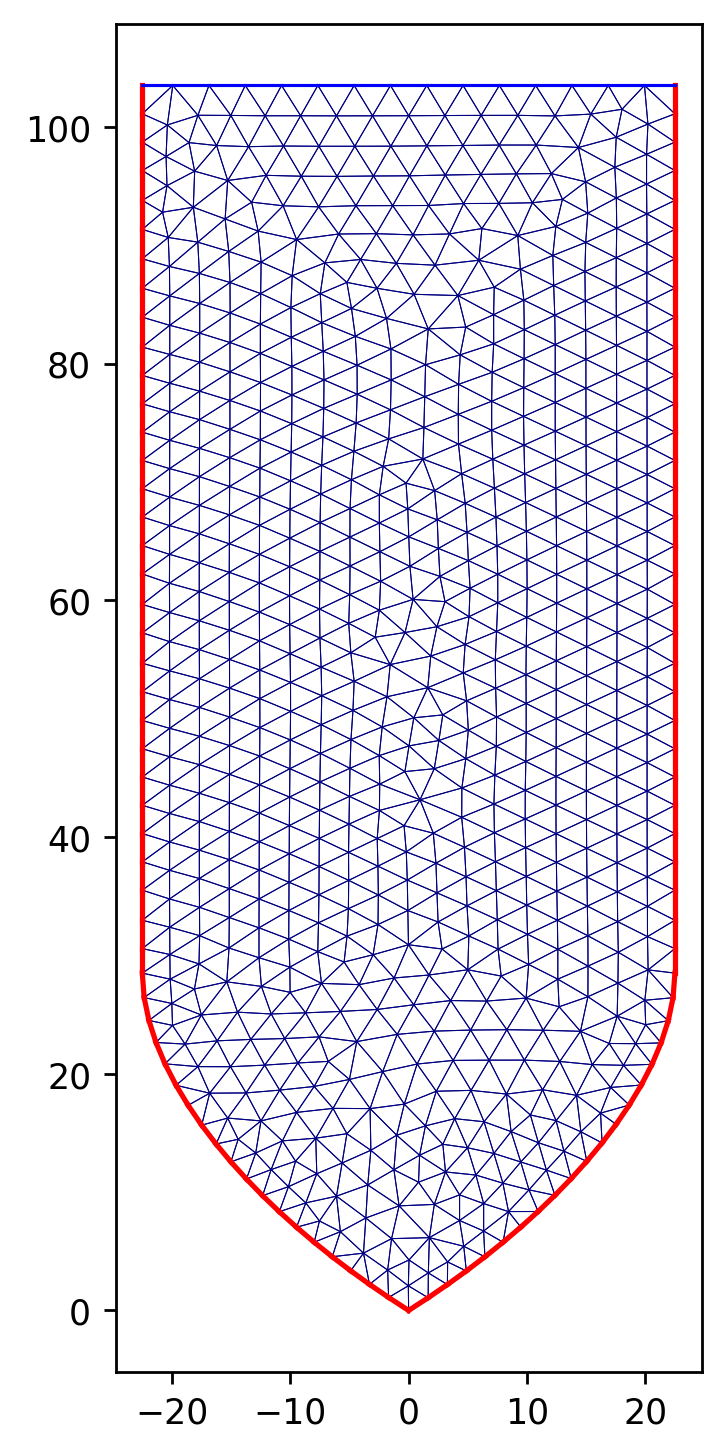

In [169]:
# create domain
geo = netgen.geom2d.CSG2d()

# create a rectangle 
hx = 30.0
hy = 50.0
zlow = -hx/2 -4
fac=1.5
poly1 = netgen.geom2d.Solid2d( [
    (0,0),
    netgen.geom2d.EdgeInfo((0, zlow/2 *fac),bc="p1_bottom_left",maxh=1.3*fac), # set bc name for segment (0,0)-(hx/2,0) and make spline3 
    (hx/2 *fac,zlow*fac),
    netgen.geom2d.EdgeInfo((hx*fac,zlow/2*fac),bc="p1_bottom_right",maxh=1.3*fac), # set bc name for segment (0,0)-(hx,0) and make spline3 
    (hx*fac,0),
    netgen.geom2d.EdgeInfo(bc="p1_right",maxh=1.5*fac),  # set bc for segment (hx,0)-(hx,hy)
    (hx*fac,hy*fac),
    netgen.geom2d.EdgeInfo(bc="p1_top"),  # set bc for segment (hx,hy)-(0,hy)
    (0,hy*fac),
    netgen.geom2d.EdgeInfo(bc="p1_left",maxh=1.5*fac), # set bc for segment (0,hy)-(0,0)
    ] )
poly1.Move((-hx/2*fac,-zlow*fac))  # center the rectangle in x and put apex at 0 in y
geo.Add(poly1)
# for splines you need to choose the intermediate point carefully.  Here we make it closer to the outer point
# so that the corner is not as much affected and is a corner 

maxhval = 2.0*fac
mesh = ngsolve.Mesh(geo.GenerateMesh(maxh=maxhval))
print(mesh.GetBoundaries())

cgle.draw_mesh(mesh,ofile=notebookroot+'mesh2.png',figsize=(4,7),d_boundaries='p1_bottom_left|p1_bottom_right|p1_right|p1_left',\
              n_boundaries='p1_top')  

In [61]:
fes = cgle.mkfes(mesh,korder,bndlist0) # make finite element system, with Dirichlet boundary 
gfu = ngsolve.GridFunction(fes) # make the field to hold the solution 
gfu_bnd = mkbnd_lr(fes,mesh,bl_real=-1.1)  # create boundary vals (fixed, non-zero Dirichlet)

sig = 0.01 # tiny bit of extra noise 
cgle.gen_init(gfu,mesh,0,sig,maxhval,A_r0=0.9,A_i0=0)  # generate interior initial conditions gen_init(gfu,mesh,nseeds,sig,hseeds):
# the A_r0, A_i0 are the mean initial field value 

cgle.set_on_boundary(gfu,gfu_bnd,fes) # update all dirichlet boundaries on gfu using gfu_bnd
scene=Draw(cgle.norm_gfu(gfu),mesh, min=0,max=1.2,\
           settings = {  "Colormap" : { "ncolors" : 20 } , "Objects" : {"Wireframe" : False}})

time = 0

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Colormap': {'ncolors': 20}, …

In [22]:
alpha = 3; beta = 0.2  # choose a nice pattern, Aranson form of PDE
clabel = r'$\alpha=${:.1f}, '.format(alpha) + r'$\beta=${:.1f}'.format(beta) 
figparms[0] = clabel
figparms[2] = (6,6)

invastar, a_lap, b_op, minv  = cgle.mk_ops(fes,alpha,dt)  # construct operators 
ofileroot = notebookroot+'_b1c_'
cgle.Aranson_to_Chate(alpha,beta)

time = cgle.TimeStepping_CN(fes,gfu,scene,invastar, a_lap,minv,beta, dt, t0=time,tdur=200,nsamples = 200,gfun_op = True,uform='Aran',\
                         poutput=True,ofileroot=ofileroot,figparms=figparms)
# works if gfun_op = True, and False and if we used either form of the non-linear operator as of 10/20/2026 


 b_1=-3.00 b_3 =5.00
craete bilinearformapplication
 201.960  CGLE_pin_v00__b1c_000.png
 203.960  CGLE_pin_v00__b1c_001.png
 205.960  CGLE_pin_v00__b1c_002.png
 207.960  CGLE_pin_v00__b1c_003.png
 209.960  CGLE_pin_v00__b1c_004.png
 211.960  CGLE_pin_v00__b1c_005.png
 213.960  CGLE_pin_v00__b1c_006.png
 215.960  CGLE_pin_v00__b1c_007.png
 217.960  CGLE_pin_v00__b1c_008.png
 219.960  CGLE_pin_v00__b1c_009.png
 221.960  CGLE_pin_v00__b1c_010.png
 223.960  CGLE_pin_v00__b1c_011.png
 225.960  CGLE_pin_v00__b1c_012.png
 227.960  CGLE_pin_v00__b1c_013.png
 229.960  CGLE_pin_v00__b1c_014.png
 231.960  CGLE_pin_v00__b1c_015.png
 233.960  CGLE_pin_v00__b1c_016.png
 235.960  CGLE_pin_v00__b1c_017.png
 237.960  CGLE_pin_v00__b1c_018.png
 239.960  CGLE_pin_v00__b1c_019.png
 241.960  CGLE_pin_v00__b1c_020.png
 243.960  CGLE_pin_v00__b1c_021.png
 245.960  CGLE_pin_v00__b1c_022.png
 247.960  CGLE_pin_v00__b1c_023.png
 249.960  CGLE_pin_v00__b1c_024.png
 251.960  CGLE_pin_v00__b1c_025.png
 253.960  CG

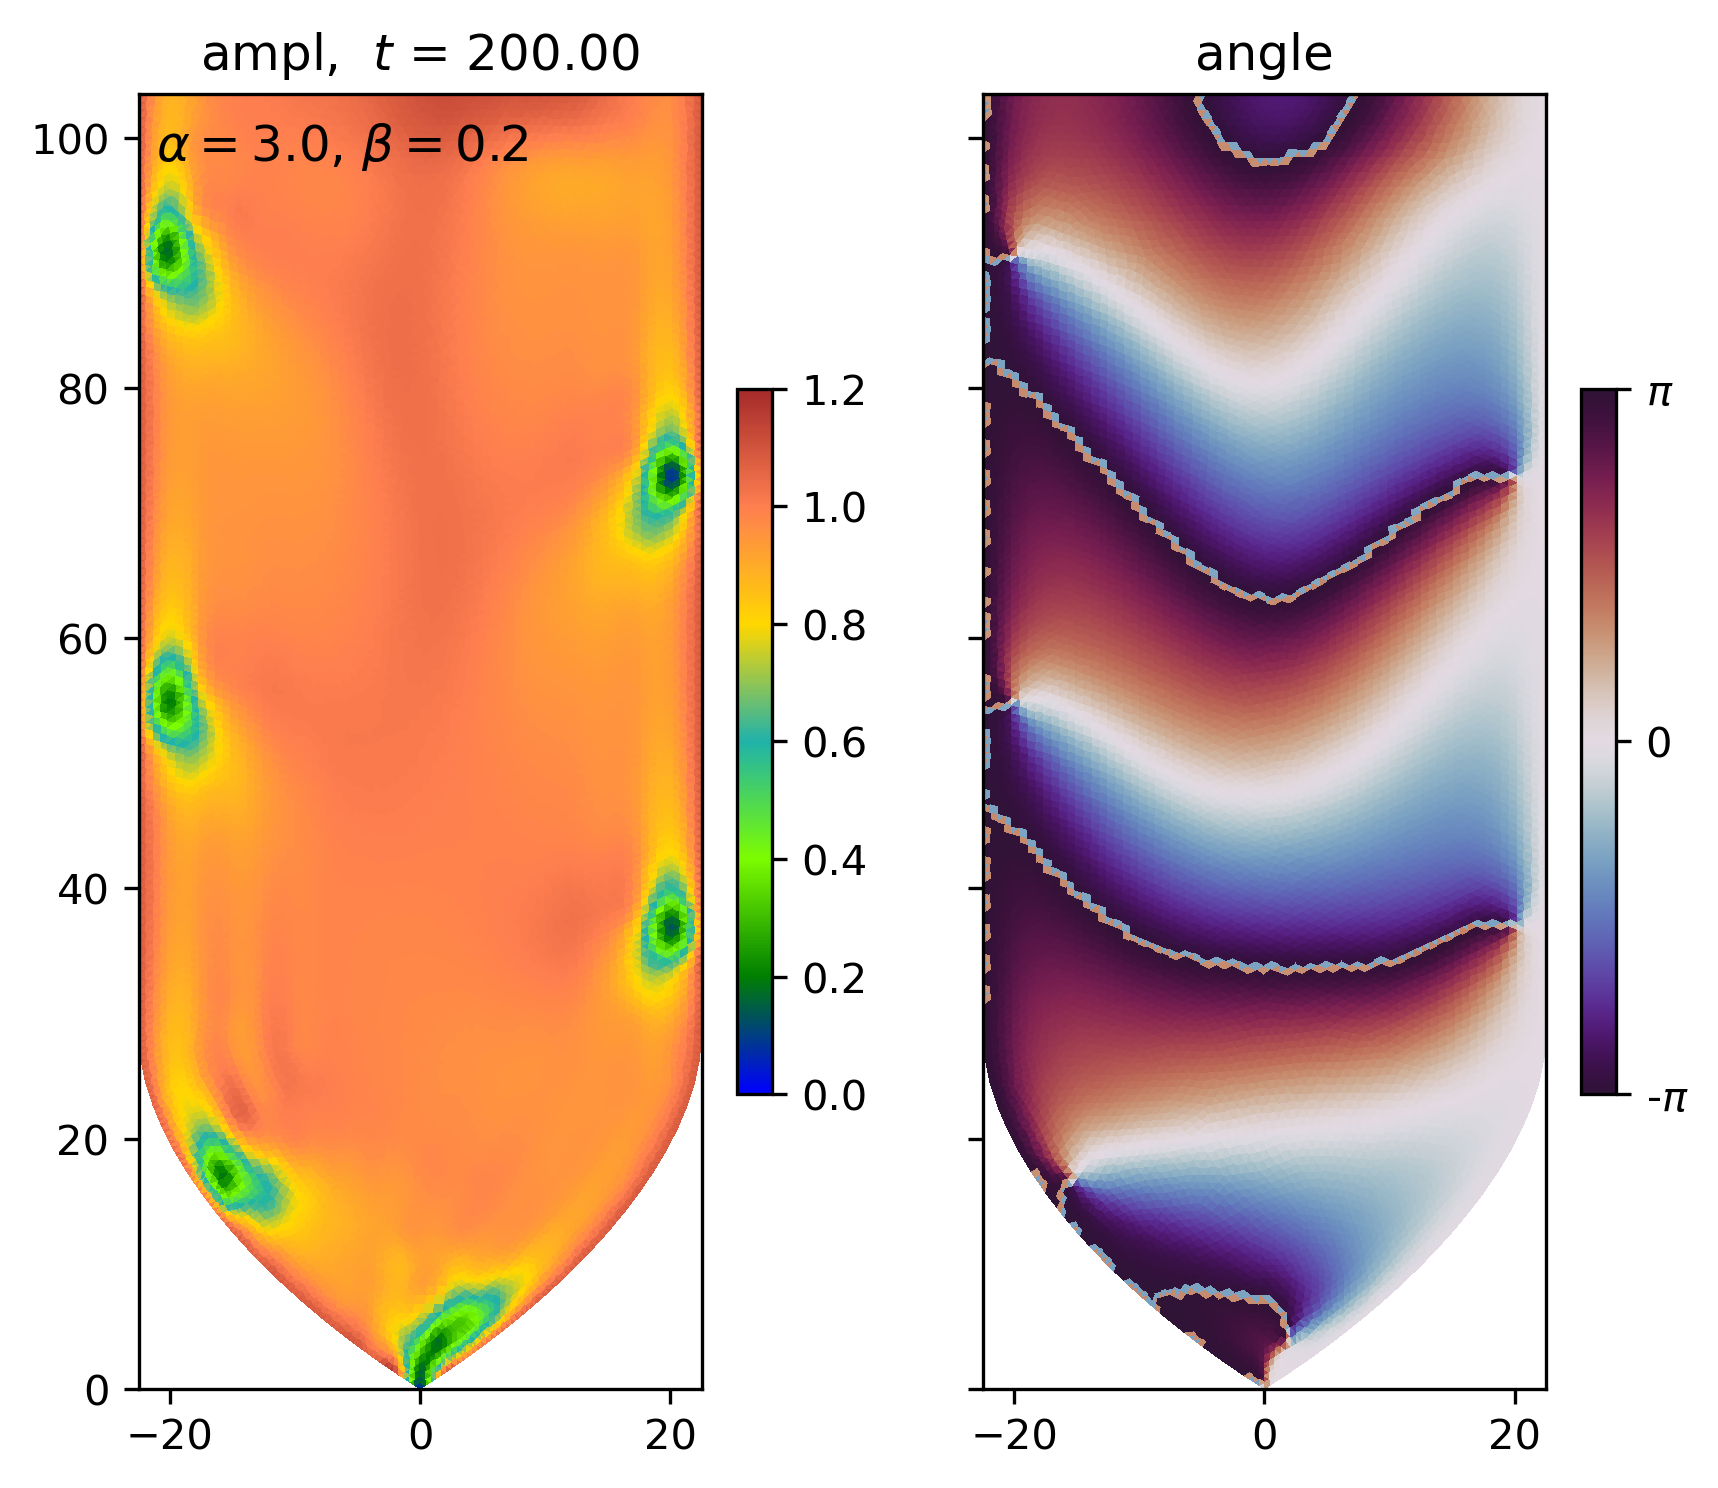

In [21]:

ofile = ofileroot + '_snap.png'
cgle.disp(mesh,gfu,time,ofile=ofile,draw_mesh=False,subdivn=2,figsize=(6,6),label=clabel,labelpos=[0.03,0.98])
cgle.disp(mesh,gfu,time,ofile='',draw_mesh=False,subdivn=2,figsize=(6,6),label=clabel,labelpos=[0.03,0.98])